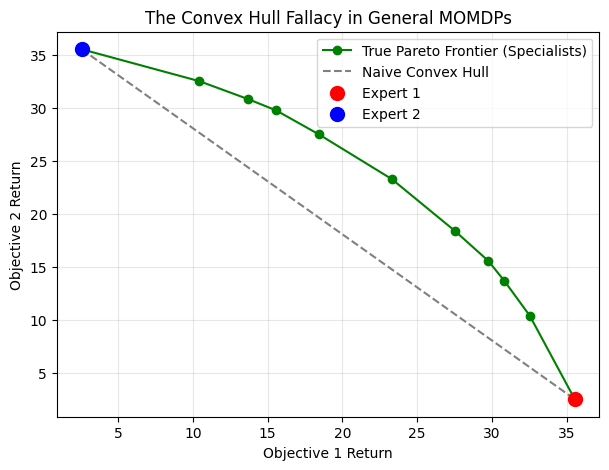

In [4]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt


def save_frontier_json(frontier, ws, path: str | Path):
    """Save plotting data (ws + frontier) to a local JSON file."""
    path = Path(path)
    payload = {
        "ws": [float(x) for x in ws],
        "frontier": [[float(v[0]), float(v[1])] for v in frontier],
    }
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, indent=2), encoding="utf-8")


def load_frontier_json(path: str | Path):
    """Load plotting data from JSON; returns (ws: np.ndarray, frontier: np.ndarray)."""
    path = Path(path)
    payload = json.loads(path.read_text(encoding="utf-8"))
    ws = np.asarray(payload["ws"], dtype=float)
    frontier = np.asarray(payload["frontier"], dtype=float)
    return ws, frontier


class MultiObjectiveGridWorld:
    """
    A General Multi-Objective GridWorld.
    Can be extended to M > 2 objectives and arbitrary sizes.
    """
    def __init__(self, height=7, width=7, slip_prob=0.05):
        self.height = height
        self.width = width
        self.n_states = height * width
        self.n_actions = 5  # Up, Down, Left, Right, Stay
        self.n_objectives = 2

        # Reward Matrix: [S, A, M]
        self.rewards = np.zeros((self.n_states, self.n_actions, self.n_objectives))

        for r in range(height):
            for c in range(width):
                s = self._to_idx(r, c)

                # Base rewards: Gradient towards corners
                dist_tr = abs(r - 0) + abs(c - (width - 1))  # Obj 1 Target
                dist_bl = abs(r - (height - 1)) + abs(c - 0)  # Obj 2 Target

                # Dense rewards based on proximity
                r1 = 1.0 / (1.0 + 0.5 * dist_tr)
                r2 = 1.0 / (1.0 + 0.5 * dist_bl)

                # --- Crucial Design for Non-Convexity ---
                # Extreme Bonuses (Experts will focus here)
                if r == 0 and c == width - 1:
                    r1 += 5.0
                if r == height - 1 and c == 0:
                    r2 += 5.0

                # Compromise Bonus (The "Specialist" Zone)
                # Only a policy explicitly optimizing for w=[0.5, 0.5] will value this.
                if r == height // 2 and c == width // 2:
                    r1 += 2.5
                    r2 += 2.5

                self.rewards[s, :, 0] = r1
                self.rewards[s, :, 1] = r2

    def _to_idx(self, r, c):
        return r * self.width + c

    def get_transitions(self, s, a):
        """Standard grid dynamics with slip."""
        r, c = s // self.width, s % self.width
        dr, dc = [-1, 1, 0, 0, 0], [0, 0, -1, 1, 0]  # U, D, L, R, Stay

        next_s_list = []
        # Main transition
        nr, nc = np.clip(r + dr[a], 0, self.height - 1), np.clip(c + dc[a], 0, self.width - 1)
        next_s_list.append((1.0, nr * self.width + nc))
        return next_s_list


# --- Solver Logic (Exact Value Iteration) ---
def solve_scalarized_vi(env, w, gamma=0.9):
    """Find optimal policy for scalar reward w^T * R"""
    V = np.zeros(env.n_states)
    R_scalar = (env.rewards * w.reshape(1, 1, -1)).sum(axis=2)

    for _ in range(200):  # Simple VI loop
        for s in range(env.n_states):
            q_vals = []
            for a in range(env.n_actions):
                # Simplified deterministic transition for clarity
                ns = env.get_transitions(s, a)[0][1]
                q_vals.append(R_scalar[s, a] + gamma * V[ns])
            V[s] = max(q_vals)

    # Extract Greedy Policy
    policy = np.zeros(env.n_states, dtype=int)
    for s in range(env.n_states):
        ns_list = [env.get_transitions(s, a)[0][1] for a in range(env.n_actions)]
        qs = [R_scalar[s, a] + gamma * V[ns] for a, ns in enumerate(ns_list)]
        policy[s] = np.argmax(qs)
    return policy


def evaluate_vec_return(env, policy, gamma=0.9):
    """Compute Vector Value V = [v1, v2]"""
    V = np.zeros((env.n_states, env.n_objectives))
    for _ in range(200):
        for s in range(env.n_states):
            a = policy[s]
            ns = env.get_transitions(s, a)[0][1]
            V[s] = env.rewards[s, a] + gamma * V[ns]
    return V.mean(axis=0)  # Average value across map


# --- Execution & Plotting ---
env = MultiObjectiveGridWorld()
ws = np.linspace(0, 1, 21)
frontier = []

for w1 in ws:
    w = np.array([w1, 1 - w1])
    pi = solve_scalarized_vi(env, w)
    ret = evaluate_vec_return(env, pi)
    frontier.append(ret)

# Save plot data to local JSON
save_frontier_json(frontier, ws, Path("./frontier.json"))

# Identify Corners
expert_1 = frontier[-1]  # w=[1,0]
expert_2 = frontier[0]  # w=[0,1]

# Plot
px, py = zip(*frontier)
plt.figure(figsize=(7, 5))
plt.plot(px, py, "o-", color="green", label="True Pareto Frontier (Specialists)")
plt.plot(
    [expert_2[0], expert_1[0]],
    [expert_2[1], expert_1[1]],
    "--",
    color="gray",
    label="Naive Convex Hull",
)
plt.scatter([expert_1[0]], [expert_1[1]], s=100, c="red", zorder=5, label="Expert 1")
plt.scatter([expert_2[0]], [expert_2[1]], s=100, c="blue", zorder=5, label="Expert 2")
plt.title("The Convex Hull Fallacy in General MOMDPs")
plt.xlabel("Objective 1 Return")
plt.ylabel("Objective 2 Return")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()